# Choose smoothness and shrink unnecessary terms

A smooth needs enough basis functions to represent the relationship, but it also needs a penalty to avoid fitting noise. These are separate choices.

We will simulate a simple effect, a more irregular effect, and an irrelevant predictor. The example compares limited basis capacity, stronger smoothing, and penalties that can shrink an entire term toward zero.

## Generate two effects and an irrelevant predictor

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from nampy.gam import GAM

rng = np.random.default_rng(102)
data = pd.DataFrame(rng.uniform(0, 1, (700, 3)), columns=["x", "z", "noise"])
functions = {"x": lambda x: np.sin(2*np.pi*x), "z": lambda z: .6*np.sin(8*np.pi*z), "noise": lambda x: np.zeros_like(x)}
data["y"] = functions["x"](data.x) + functions["z"](data.z) + rng.normal(0, .3, len(data))
train, test = train_test_split(data, test_size=.25, random_state=102)
models = {}

## Fit a basis that is too small

With four basis functions, the irregular z effect cannot express its repeated oscillations, regardless of the selected penalty.

In [2]:
models["Small basis"] = GAM(formula="y ~ s(x, bs='cr', k=4) + s(z, bs='cr', k=4) + s(noise, bs='cr', k=4)", smoothing_method="reml", optimize_smoothing=True).fit(train)

## Increase the basis dimension

Raising k enlarges the function space. REML still controls roughness within that space. The basis diagnostic is evidence to inspect, rather than an automatic acceptance rule.

In [3]:
formula = "y ~ s(x, bs='cr', k=18) + s(z, bs='cr', k=18) + s(noise, bs='cr', k=18)"
models["Estimated smoothness"] = GAM(formula=formula, smoothing_method="reml", optimize_smoothing=True).fit(train)
basis_results = pd.concat({name: model.k_check(n_rep=40, seed=102) for name, model in models.items()}, names=["Model", "Term"])
basis_results.reset_index().style.hide(axis="index").format(precision=3)

Model,Term,k_prime,edf,k_index,p_value
Small basis,s(x),3,2.994,1.031,0.750
Small basis,s(z),3,2.878,0.361,0.000
Small basis,s(noise),3,1.705,1.022,0.675
Estimated smoothness,s(x),17,9.418,1.043,0.875
Estimated smoothness,s(z),17,16.087,1.090,1.000
Estimated smoothness,s(noise),17,1.438,0.965,0.200


## Compare fixed and estimated smoothing

Fixed penalties are illustrative choices declared before test evaluation. Their values are not optimized against test outcomes.

In [4]:
models["Fixed weak penalty"] = GAM(formula=formula, smoothing_method="fixed", smoothing_params=[.001]*3).fit(train)
models["Fixed strong penalty"] = GAM(formula=formula, smoothing_method="fixed", smoothing_params=[100]*3).fit(train)

## Penalize unnecessary terms

An ordinary roughness penalty can leave an unpenalized component of a smooth. Increasing its penalty therefore need not remove the term entirely. Shrinkage bases and additional null-space penalties allow the whole effect to be penalized.

The shrinkage basis and `select=True` are separate models here.

In [5]:
models["Shrinkage basis"] = GAM(formula=formula.replace("'cr'", "'cs'"), smoothing_method="reml", optimize_smoothing=True).fit(train)
models["Additional selection penalty"] = GAM(formula=formula, select=True, smoothing_method="reml", optimize_smoothing=True).fit(train)
rows = []
penalties = []
for name, model in models.items():
    result = model.fit_result()
    noise_edf = sum(term.edf for term in result.term_results if term.label.startswith("s(noise,"))
    rows.append({"Model": name, "Test RMSE": mean_squared_error(test.y, model.predict(test))**.5,
                 "Total EDF": result.edf_total, "Irrelevant-feature EDF": noise_edf})
    for term in result.term_results:
        for penalty, value in enumerate(term.smoothing_values):
            penalties.append({"Model": name, "Term": term.label, "Penalty within term": penalty + 1,
                              "Smoothing parameter": value})
pd.DataFrame(rows).style.hide(axis="index").format(precision=3)

Model,Test RMSE,Total EDF,Irrelevant-feature EDF
Small basis,0.527,8.576,1.705
Estimated smoothness,0.320,27.942,1.438
Fixed weak penalty,0.322,51.998,16.999
Fixed strong penalty,0.362,28.481,9.152
Shrinkage basis,0.320,26.679,0.446
Additional selection penalty,0.321,27.254,0.783


In [6]:
from IPython.display import HTML, display
penalty_table = pd.DataFrame(penalties).to_html(index=False, float_format=lambda x: f"{x:.3g}")
display(HTML("<details><summary>Per-penalty smoothing parameters</summary>" + penalty_table + "</details>"))

Model,Term,Penalty within term,Smoothing parameter
Small basis,"s(x, bs='cr', k=4)",1,0.266
Small basis,"s(z, bs='cr', k=4)",1,5.99
Small basis,"s(noise, bs='cr', k=4)",1,278
Estimated smoothness,"s(x, bs='cr', k=18)",1,84.8
Estimated smoothness,"s(z, bs='cr', k=18)",1,1.89
Estimated smoothness,"s(noise, bs='cr', k=18)",1,2.17e+05
Fixed weak penalty,"s(x, bs='cr', k=18)",1,0.001
Fixed weak penalty,"s(z, bs='cr', k=18)",1,0.001
Fixed weak penalty,"s(noise, bs='cr', k=18)",1,0.001
Fixed strong penalty,"s(x, bs='cr', k=18)",1,100


## Compare effect recovery and prediction

The dashed curves are centered using the training inputs, matching the fitted contribution reference. The irrelevant predictor has a true contribution of zero. Test RMSE compares all fits on a common scale; raw GCV and REML criteria are not ranked against one another.

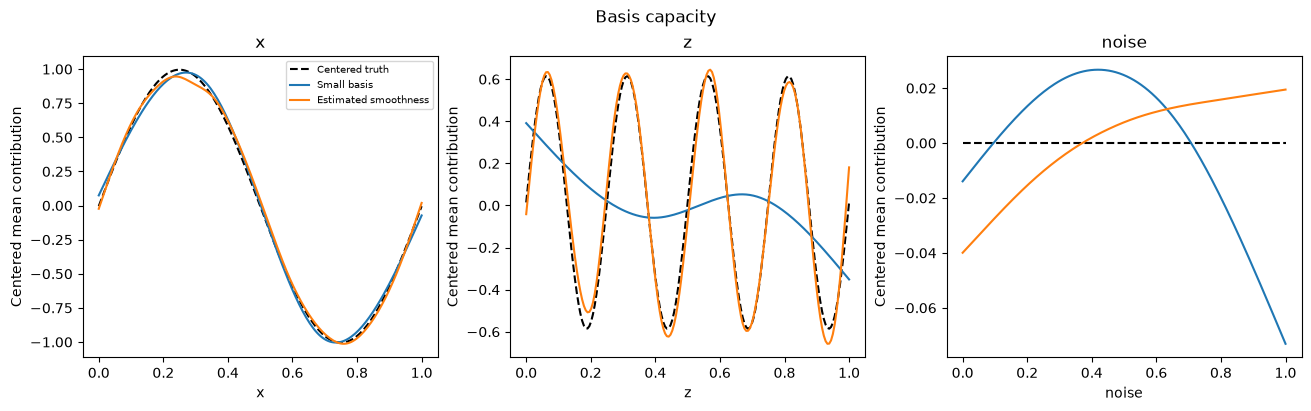

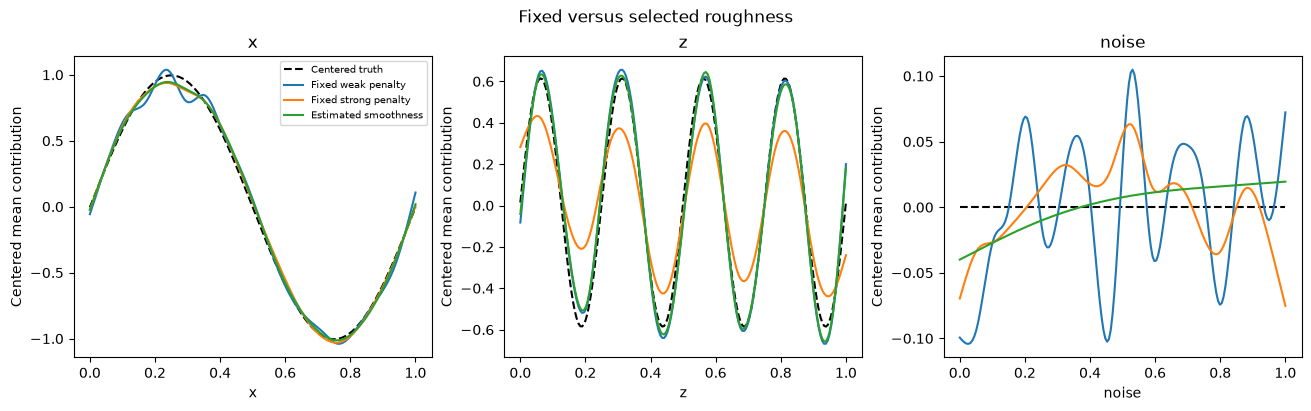

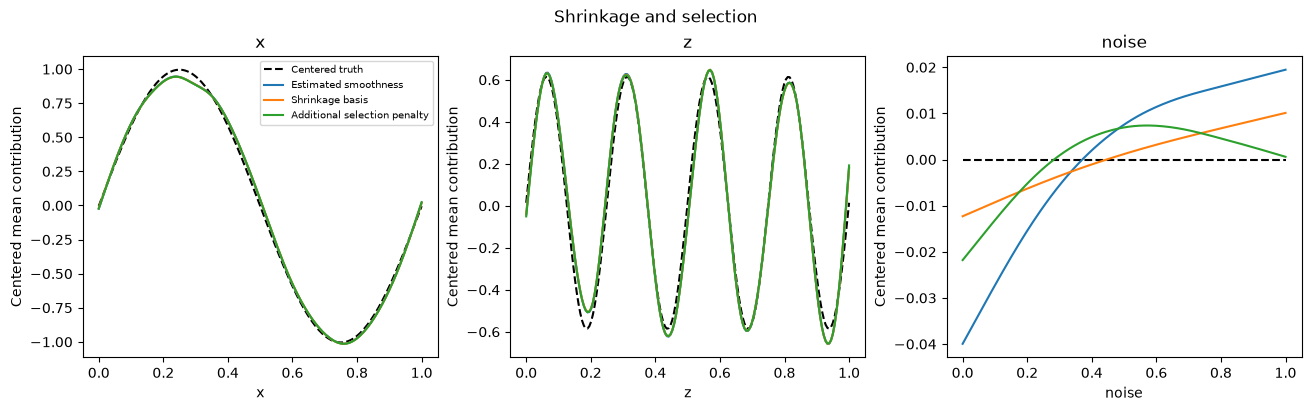

In [7]:
values = np.linspace(0, 1, 180)
comparisons = {
    "Basis capacity": ["Small basis", "Estimated smoothness"],
    "Fixed versus selected roughness": ["Fixed weak penalty", "Fixed strong penalty", "Estimated smoothness"],
    "Shrinkage and selection": ["Estimated smoothness", "Shrinkage basis", "Additional selection penalty"],
}
for title, selected_names in comparisons.items():
    figure, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
    figure.suptitle(title)
    for axis, feature in zip(axes, functions):
        grid = pd.DataFrame({name: np.full(len(values), train[name].median()) for name in functions})
        grid[feature] = values
        axis.plot(values, functions[feature](values) - functions[feature](train[feature]).mean(), "k--", label="Centered truth")
        for name in selected_names:
            model = models[name]
            result = model.fit_result()
            terms = np.asarray(model.predict(grid, type="terms"))
            reference_terms = np.asarray(model.predict(train, type="terms"))
            columns = [i for i, term in enumerate(result.term_results) if term.label.startswith(f"s({feature},")]
            effect = (terms[:, columns] - reference_terms[:, columns].mean(axis=0)).sum(axis=1)
            axis.plot(values, effect, label=name)
        axis.set(title=feature, xlabel=feature, ylabel="Centered mean contribution")
    axes[0].legend(fontsize=7)
    plt.show()
    plt.close(figure)

The small basis misses the oscillating z effect: its k diagnostic has index 0.36 and simulated p-value 0 in this run. Increasing capacity lowers test RMSE from 0.527 to 0.320. Weak fixed penalties retain more wiggles in the irrelevant feature; shrinkage and selection penalties reduce that effect without materially improving test RMSE.